<a href="https://colab.research.google.com/github/ImNotDanish05/2026_Pembelajaran-Mesin_TI-3A/blob/main/Week_10/Penilitian_Regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import urllib.request
import pandas as pd

# 1. Download the file directly to the local Colab environment
url = 'http://statlearning.com/s/Advertising.csv'
local_filename = 'Advertising.csv'
urllib.request.urlretrieve(url, local_filename)
print(f"File downloaded successfully to Colab local storage as '{local_filename}'\n")

# 2. Load and inspect the downloaded local file
df_local = pd.read_csv(local_filename, index_col=0)

# Display the top rows
display(df_local.head())

# Show info about the data
print("\nLocal Dataset Info:")
df_local.info()

File downloaded successfully to Colab local storage as 'Advertising.csv'



,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9



Local Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB


PENELITIAN REGRESI ADVERTISING DATASET

DATASET BERHASIL DIMUAT
Jumlah data awal       : 200
Jumlah data digunakan  : 200
Data yang dihapus      : 0
Jumlah fitur           : 3
Variabel target        : sales

TABEL 1. STATISTIK DESKRIPTIF DATASET


,count,mean,std,min,25%,50%,75%,max,Median,Variance,Missing Values
TV,200.0000,147.0425,85.8542,0.7000,74.3750,149.7500,218.8250,296.4000,149.7500,7370.9499,0
radio,200.0000,23.2640,14.8468,0.0000,9.9750,22.9000,36.5250,49.6000,22.9000,220.4277,0
newspaper,200.0000,30.5540,21.7786,0.3000,12.7500,25.7500,45.1000,114.0000,25.7500,474.3083,0
sales,200.0000,14.0225,5.2175,1.6000,10.3750,12.9000,17.4000,27.0000,12.9000,27.2219,0



TABEL 2. MATRIKS KORELASI PEARSON


,TV,radio,newspaper,sales
TV,1.0000,0.0548,0.0566,0.7822
radio,0.0548,1.0000,0.3541,0.5762
newspaper,0.0566,0.3541,1.0000,0.2283
sales,0.7822,0.5762,0.2283,1.0000



PEMBAGIAN DATASET
Jumlah data training : 160
Jumlah data testing  : 40
Persentase training  : 80%
Persentase testing   : 20%

TABEL 3. KOEFISIEN REGRESI LINEAR BERGANDA


,Fitur,Koefisien
0,Intercept,2.9791
1,TV,0.0447
2,radio,0.1892
3,newspaper,0.0028


... (7 outputs left out)

,Algoritma,MAE Mean,MAE Std,MSE Mean,MSE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Polynomial Regression,0.4519,0.0816,0.4865,0.5007,0.6422,0.2723,0.9763,0.0247
1,Multiple Linear Regression,1.2389,0.2777,2.9122,1.5323,1.6550,0.4162,0.8475,0.0990
2,Simple Linear Regression,2.6455,0.5305,11.1085,3.9591,3.2835,0.5721,0.4528,0.2809



TABEL 8. PERBANDINGAN REGRESI LINEAR 2 DAN 3 FITUR


,Skenario,Jumlah Fitur,MAE,MSE,RMSE,R2 Score
0,Linear Regression - 2 Fitur,2,1.4443,3.1379,1.7714,0.9006
1,Linear Regression - 3 Fitur,3,1.4608,3.1741,1.7816,0.8994



MODEL TERBAIK BERDASARKAN 10-FOLD CROSS-VALIDATION
Algoritma terbaik: Polynomial Regression


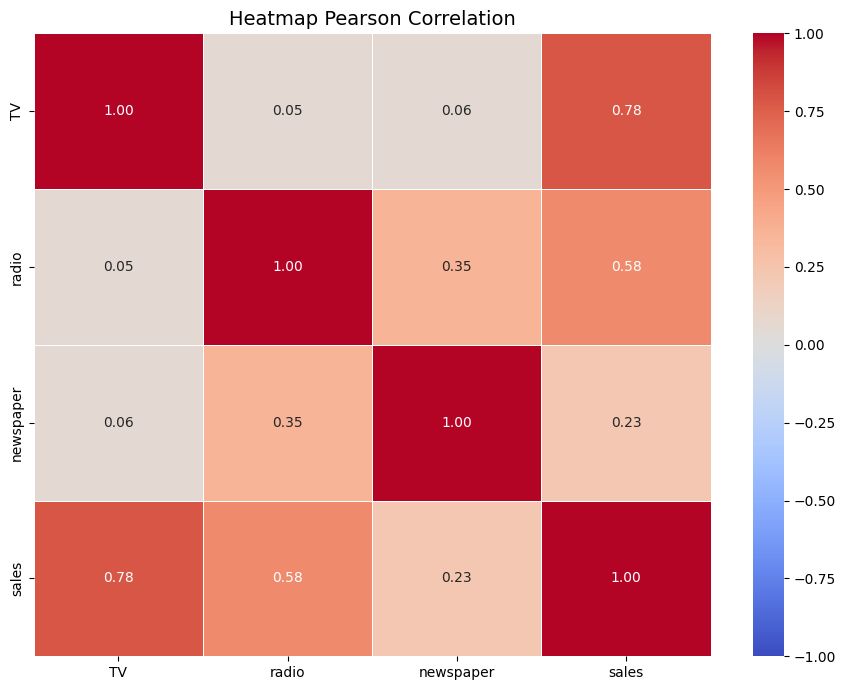

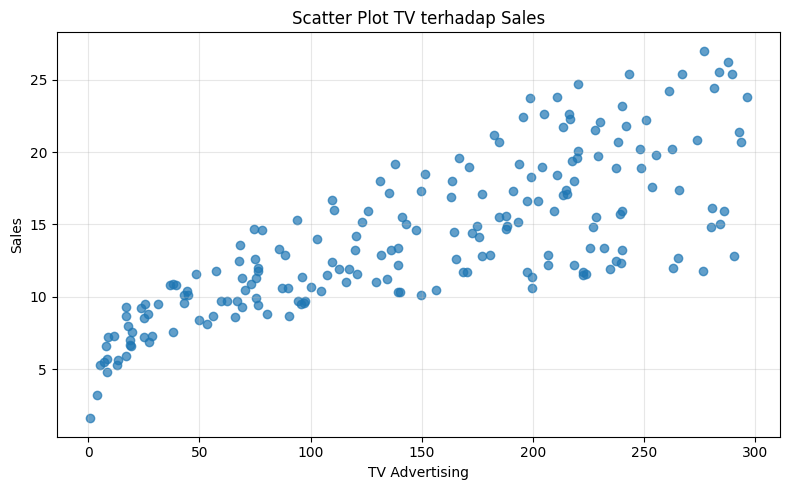

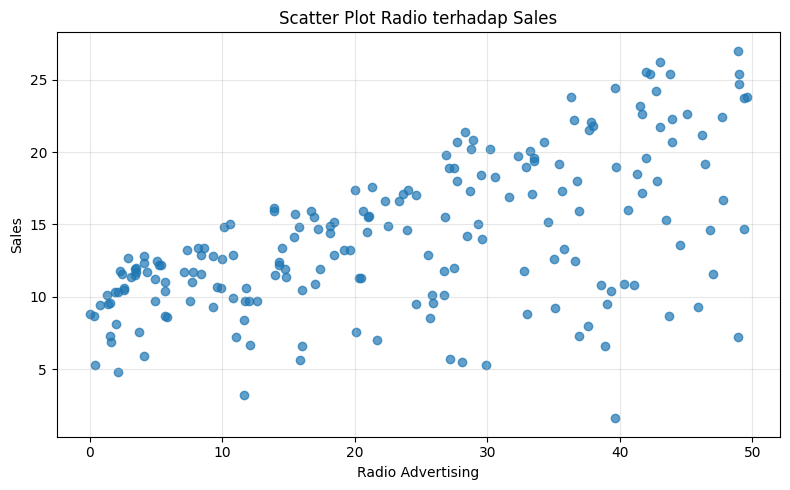

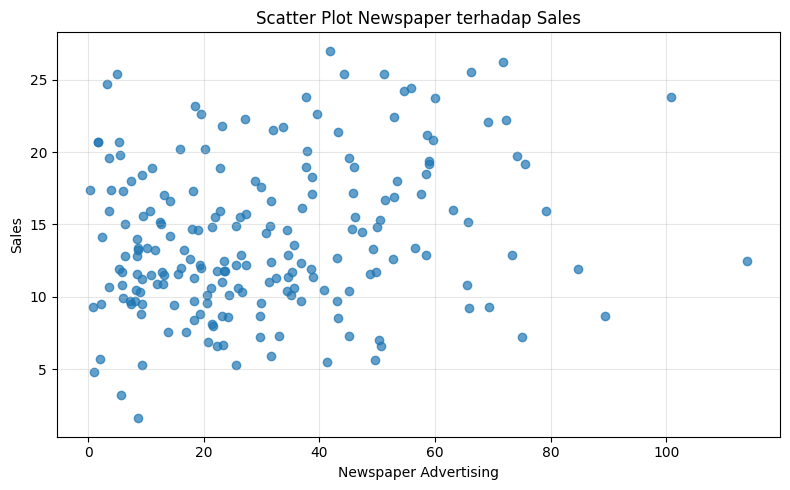

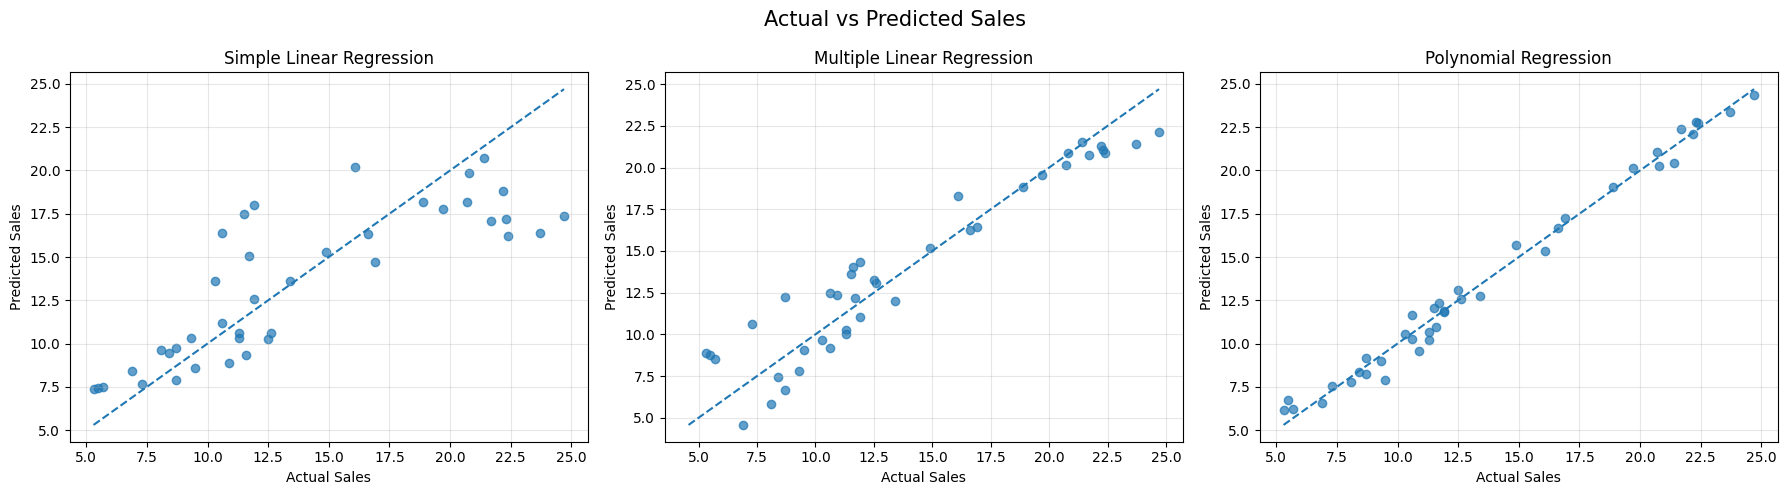

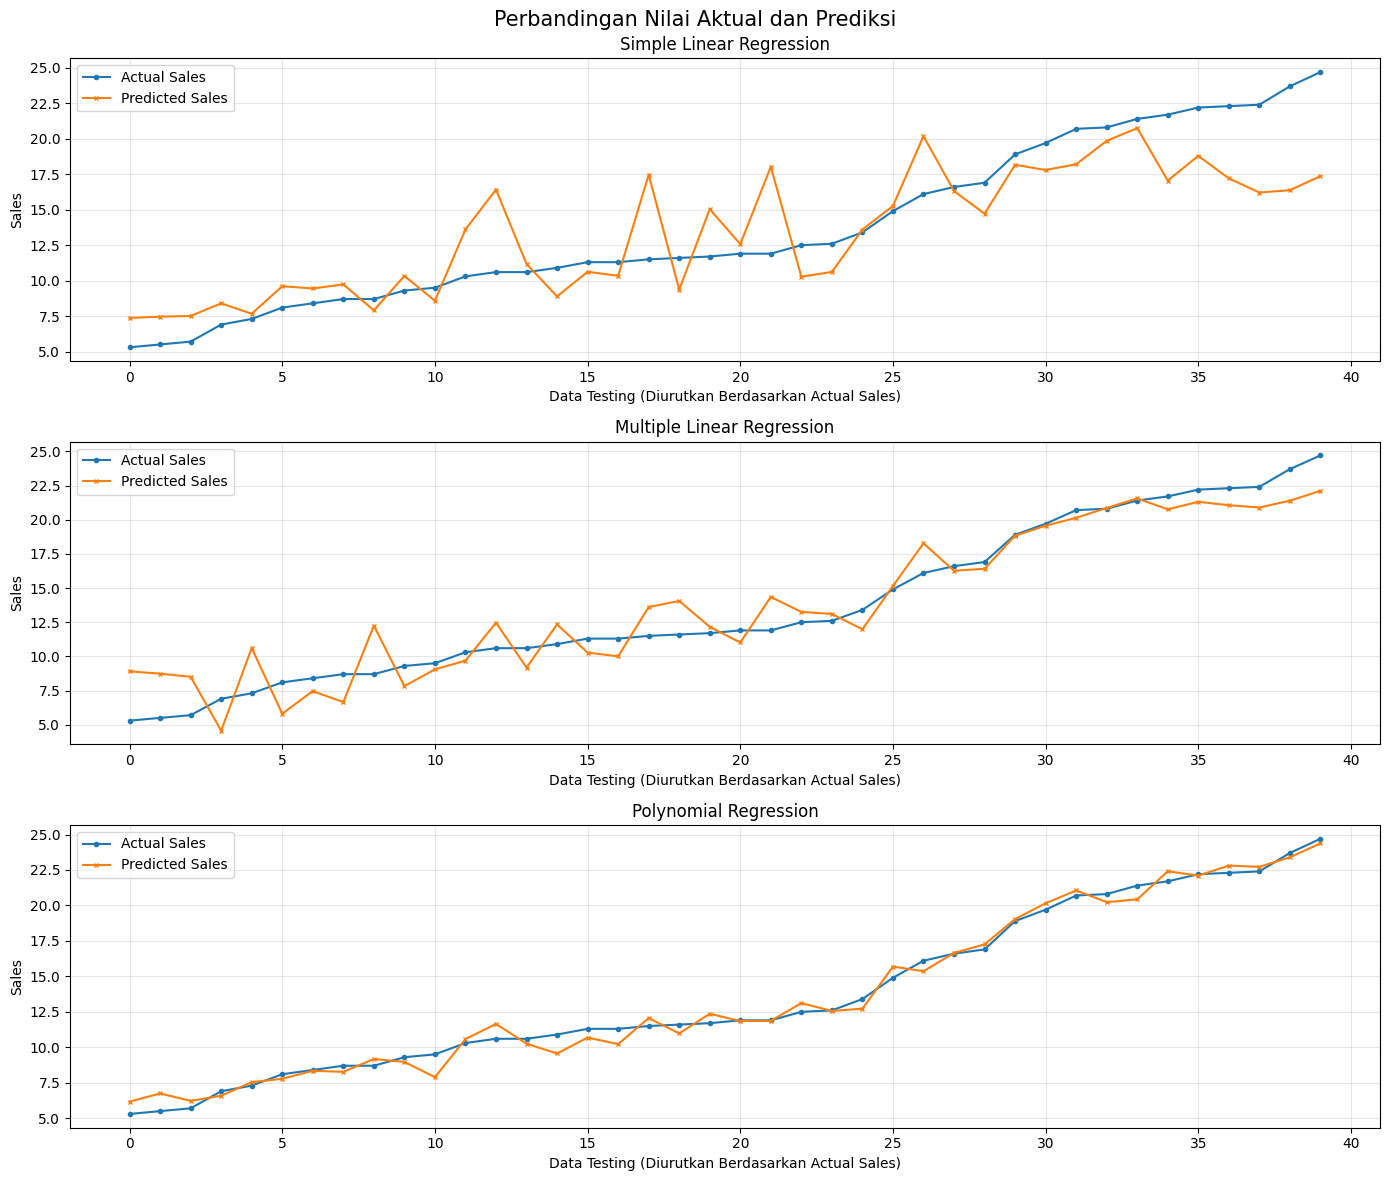

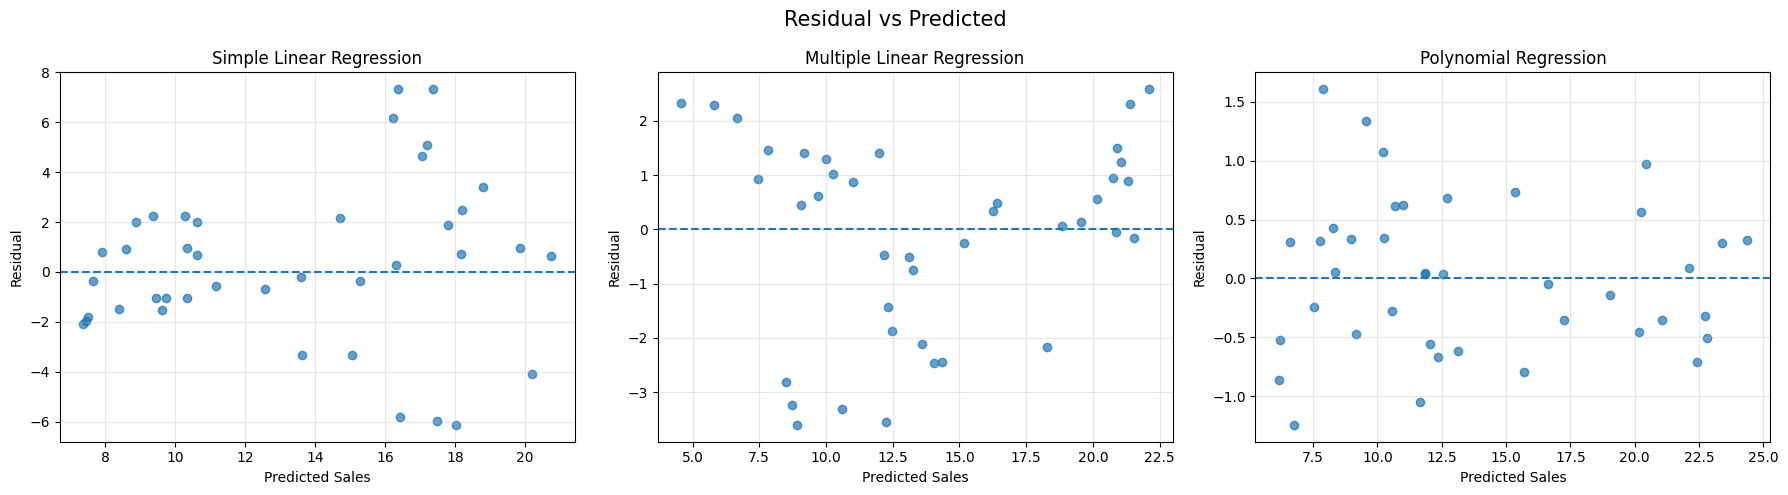

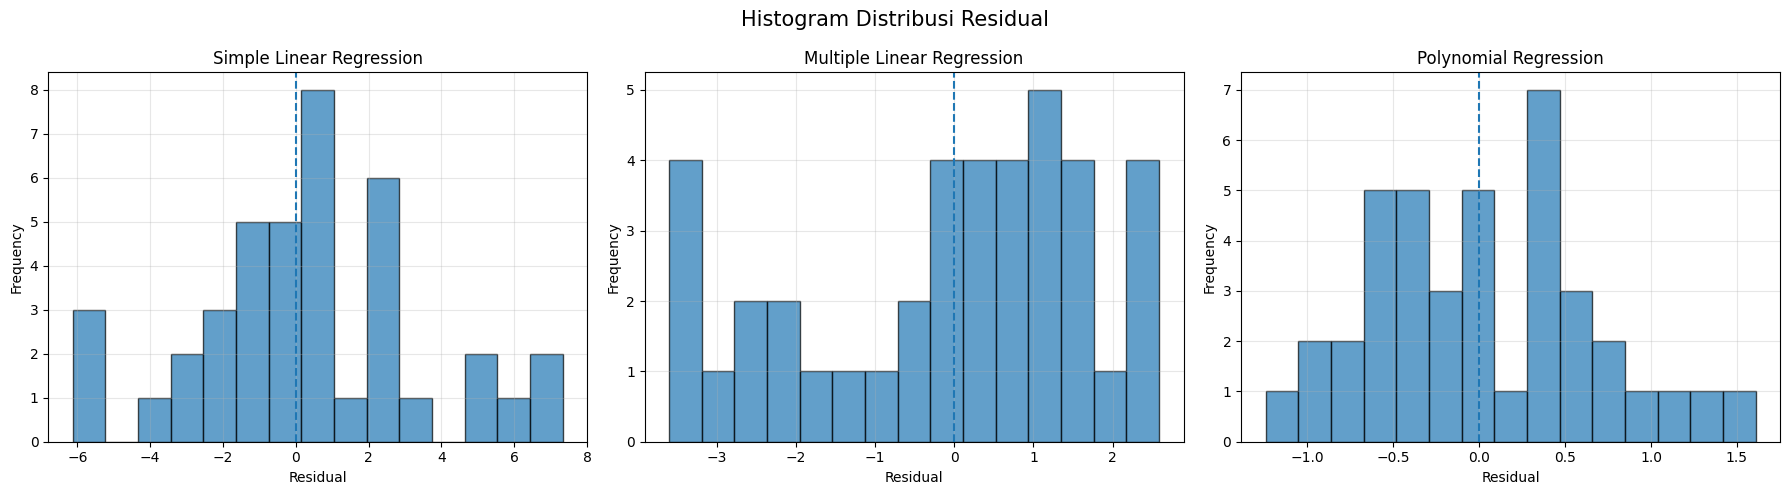

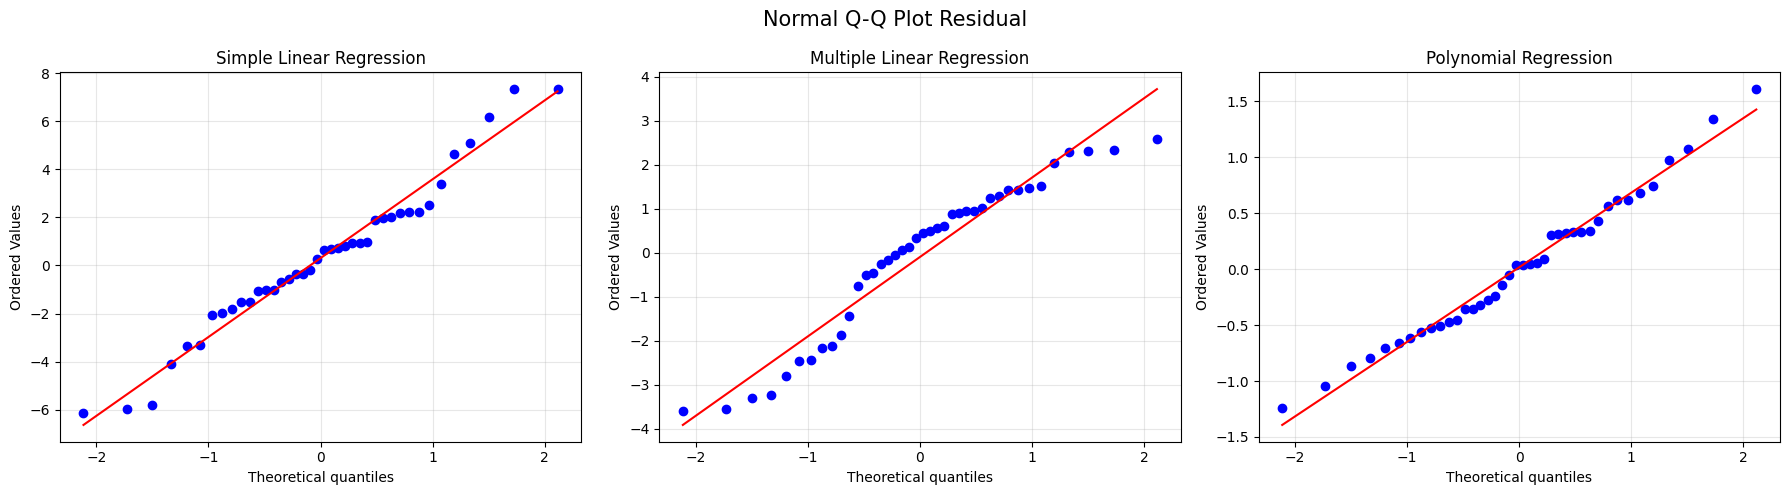


RINGKASAN HASIL PENELITIAN

Dataset                : Advertising.csv
Jumlah Data            : 200
Jumlah Fitur           : 3
Variabel Target        : sales

Data Training          : 160
Data Testing           : 40

Jumlah Algoritma       : 3
Cross-Validation       : 10-Fold

MODEL TERBAIK BERDASARKAN CROSS-VALIDATION
Algoritma              : Polynomial Regression

HASIL DATA TESTING
MAE                    : 0.5262
MSE                    : 0.4129
RMSE                   : 0.6426
R2 Score               : 0.9869

HASIL CROSS-VALIDATION
MAE Mean               : 0.4519
MAE Std                : 0.0816
RMSE Mean              : 0.6422
RMSE Std               : 0.2723
R2 Mean                : 0.9763
R2 Std                 : 0.0247

SELURUH EKSPERIMEN SELESAI


In [9]:
# ================================================================
# PENELITIAN REGRESI: ADVERTISING DATASET
# SIMPLE LINEAR, MULTIPLE LINEAR, POLYNOMIAL REGRESSION
# FEATURE: TV, RADIO, NEWSPAPER
# TARGET : SALES
# ================================================================

# 1. IMPORT LIBRARIES
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor

# ================================================================
# 2. KONFIGURASI
# ================================================================

FILE_PATH = "/content/Advertising.csv"

FEATURES = ["TV", "radio", "newspaper"]
TARGET = "sales"

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 10

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("=" * 80)
print("PENELITIAN REGRESI ADVERTISING DATASET")
print("=" * 80)

# ================================================================
# 3. LOAD DATASET
# ================================================================

df = pd.read_csv(FILE_PATH)

# Membersihkan nama kolom
df.columns = df.columns.str.strip()

# Menghapus kolom indeks tambahan jika tersedia
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Validasi kolom
required_columns = FEATURES + [TARGET]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}")

# Mengambil kolom penelitian
df = df[required_columns].copy()

# Mengubah seluruh kolom menjadi numerik
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Menghapus missing values
initial_rows = len(df)
df = df.dropna().reset_index(drop=True)
removed_rows = initial_rows - len(df)

print("\nDATASET BERHASIL DIMUAT")
print(f"Jumlah data awal       : {initial_rows}")
print(f"Jumlah data digunakan  : {len(df)}")
print(f"Data yang dihapus      : {removed_rows}")
print(f"Jumlah fitur           : {len(FEATURES)}")
print(f"Variabel target        : {TARGET}")

if len(df) < N_SPLITS:
    raise ValueError("Jumlah data tidak mencukupi untuk 10-Fold CV.")

# ================================================================
# 4. TABEL 1 - STATISTIK DESKRIPTIF DATASET
# ================================================================

print("\n" + "=" * 80)
print("TABEL 1. STATISTIK DESKRIPTIF DATASET")
print("=" * 80)

descriptive_stats = df.describe().T

descriptive_stats["Missing Values"] = df.isnull().sum()
descriptive_stats["Median"] = df.median()
descriptive_stats["Variance"] = df.var()

descriptive_stats = descriptive_stats[
    ["count", "mean", "std", "min", "25%", "50%", "75%",
     "max", "Median", "Variance", "Missing Values"]
]

display(descriptive_stats)

# ================================================================
# 5. TABEL 2 - MATRIKS KORELASI PEARSON
# ================================================================

print("\n" + "=" * 80)
print("TABEL 2. MATRIKS KORELASI PEARSON")
print("=" * 80)

correlation_matrix = df.corr(method="pearson")

display(correlation_matrix)

# ================================================================
# 6. DATA SPLITTING
# ================================================================

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("\n" + "=" * 80)
print("PEMBAGIAN DATASET")
print("=" * 80)

print(f"Jumlah data training : {len(X_train)}")
print(f"Jumlah data testing  : {len(X_test)}")
print(f"Persentase training  : {(1-TEST_SIZE)*100:.0f}%")
print(f"Persentase testing   : {TEST_SIZE*100:.0f}%")

# ================================================================
# 7. TABEL 3 - KOEFISIEN REGRESI LINEAR BERGANDA
# ================================================================

print("\n" + "=" * 80)
print("TABEL 3. KOEFISIEN REGRESI LINEAR BERGANDA")
print("=" * 80)

multiple_model_for_coef = LinearRegression()
multiple_model_for_coef.fit(X_train, y_train)

coefficient_table = pd.DataFrame({
    "Fitur": FEATURES,
    "Koefisien": multiple_model_for_coef.coef_
})

intercept_row = pd.DataFrame({
    "Fitur": ["Intercept"],
    "Koefisien": [multiple_model_for_coef.intercept_]
})

coefficient_table = pd.concat(
    [intercept_row, coefficient_table],
    ignore_index=True
)

display(coefficient_table)

print("\nPersamaan Regresi Linear Berganda:")

equation = (
    f"Sales = {multiple_model_for_coef.intercept_:.4f}"
)

for feature, coef in zip(FEATURES, multiple_model_for_coef.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f}({feature})"

print(equation)

# ================================================================
# 8. TABEL 4 - ANALISIS MULTIKOLINEARITAS (TOLERANCE DAN VIF)
# ================================================================

print("\n" + "=" * 80)
print("TABEL 4. ANALISIS MULTIKOLINEARITAS")
print("=" * 80)

vif_data = pd.DataFrame()
vif_data["Fitur"] = FEATURES

vif_values = []

for i in range(len(FEATURES)):
    vif = variance_inflation_factor(X_train[FEATURES].values, i)
    vif_values.append(vif)

vif_data["VIF"] = vif_values
vif_data["Tolerance"] = 1 / vif_data["VIF"]

def vif_interpretation(vif):
    if vif < 5:
        return "Tidak terdapat indikasi multikolinearitas kuat"
    elif vif < 10:
        return "Indikasi multikolinearitas sedang"
    else:
        return "Indikasi multikolinearitas tinggi"

vif_data["Interpretasi"] = vif_data["VIF"].apply(vif_interpretation)

display(vif_data)

# ================================================================
# 9. DEFINISI MODEL REGRESI
# ================================================================

models = {
    "Simple Linear Regression": {
        "model": LinearRegression(),
        "features": ["TV"]
    },

    "Multiple Linear Regression": {
        "model": LinearRegression(),
        "features": ["TV", "radio", "newspaper"]
    },

    "Polynomial Regression": {
        "model": Pipeline([
            ("polynomial", PolynomialFeatures(
                degree=2,
                include_bias=False
            )),
            ("scaler", StandardScaler()),
            ("regression", LinearRegression())
        ]),
        "features": ["TV", "radio", "newspaper"]
    }
}

# ================================================================
# 10. TRAINING DAN PREDIKSI
# ================================================================

trained_models = {}
predictions = {}
residuals = {}

evaluation_results = []

for model_name, config in models.items():

    selected_features = config["features"]

    X_train_model = X_train[selected_features]
    X_test_model = X_test[selected_features]

    model = config["model"]

    # Training
    model.fit(X_train_model, y_train)

    # Prediksi
    y_pred = model.predict(X_test_model)

    # Penyimpanan
    trained_models[model_name] = model
    predictions[model_name] = y_pred
    residuals[model_name] = y_test.values - y_pred

    # Evaluasi
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Algoritma": model_name,
        "Jumlah Fitur": len(selected_features),
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

evaluation_table = pd.DataFrame(evaluation_results)

# ================================================================
# 11. TABEL 5 - PERBANDINGAN NILAI AKTUAL DAN PREDIKSI
# ================================================================

print("\n" + "=" * 80)
print("TABEL 5. PERBANDINGAN NILAI AKTUAL DAN PREDIKSI")
print("=" * 80)

prediction_table = pd.DataFrame({
    "Nilai Aktual": y_test.values
})

for model_name, y_pred in predictions.items():
    prediction_table[f"Prediksi - {model_name}"] = y_pred
    prediction_table[f"Residual - {model_name}"] = y_test.values - y_pred

prediction_table.insert(
    0,
    "Index Data",
    X_test.index.values
)

display(prediction_table)

# ================================================================
# 12. TABEL 6 - EVALUASI MODEL
# ================================================================

print("\n" + "=" * 80)
print("TABEL 6. EVALUASI MODEL REGRESI")
print("=" * 80)

display(
    evaluation_table.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

# ================================================================
# 13. TABEL 7 - 10-FOLD CROSS VALIDATION
# ================================================================

print("\n" + "=" * 80)
print("TABEL 7. EVALUASI 10-FOLD CROSS-VALIDATION")
print("=" * 80)

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "R2": "r2"
}

cv_results = []

for model_name, config in models.items():

    selected_features = config["features"]
    model = config["model"]

    scores = cross_validate(
        model,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    # Konversi skor negatif menjadi positif
    mae_scores = -scores["test_MAE"]
    mse_scores = -scores["test_MSE"]
    rmse_scores = np.sqrt(mse_scores)
    r2_scores = scores["test_R2"]

    cv_results.append({
        "Algoritma": model_name,
        "MAE Mean": mae_scores.mean(),
        "MAE Std": mae_scores.std(),
        "MSE Mean": mse_scores.mean(),
        "MSE Std": mse_scores.std(),
        "RMSE Mean": rmse_scores.mean(),
        "RMSE Std": rmse_scores.std(),
        "R2 Mean": r2_scores.mean(),
        "R2 Std": r2_scores.std()
    })

cv_table = pd.DataFrame(cv_results)

display(
    cv_table.sort_values(
        by="RMSE Mean",
        ascending=True
    ).reset_index(drop=True)
)

# ================================================================
# 14. TABEL 8 - PERBANDINGAN REGRESI LINEAR 2 DAN 3 FITUR
# ================================================================

print("\n" + "=" * 80)
print("TABEL 8. PERBANDINGAN REGRESI LINEAR 2 DAN 3 FITUR")
print("=" * 80)

feature_combinations = {
    "Linear Regression - 2 Fitur": ["TV", "radio"],
    "Linear Regression - 3 Fitur": ["TV", "radio", "newspaper"]
}

optional_results = []

for scenario, selected_features in feature_combinations.items():

    model = LinearRegression()

    model.fit(
        X_train[selected_features],
        y_train
    )

    y_pred = model.predict(
        X_test[selected_features]
    )

    optional_results.append({
        "Skenario": scenario,
        "Jumlah Fitur": len(selected_features),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2 Score": r2_score(y_test, y_pred)
    })

optional_table = pd.DataFrame(optional_results)

display(optional_table)

# ================================================================
# 15. MENENTUKAN MODEL TERBAIK BERDASARKAN CROSS-VALIDATION
# ================================================================

best_model_name = cv_table.loc[
    cv_table["RMSE Mean"].idxmin(),
    "Algoritma"
]

best_model = trained_models[best_model_name]
best_prediction = predictions[best_model_name]
best_residual = residuals[best_model_name]

print("\n" + "=" * 80)
print("MODEL TERBAIK BERDASARKAN 10-FOLD CROSS-VALIDATION")
print("=" * 80)

print(f"Algoritma terbaik: {best_model_name}")

# ================================================================
# 16. GRAFIK 1 - HEATMAP KORELASI PEARSON
# ================================================================

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Pearson Correlation", fontsize=14)
plt.tight_layout()
plt.show()

# ================================================================
# 17. GRAFIK 2 - SCATTER PLOT TV TERHADAP SALES
# ================================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["TV"],
    df["sales"],
    alpha=0.7
)

plt.xlabel("TV Advertising")
plt.ylabel("Sales")
plt.title("Scatter Plot TV terhadap Sales")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 18. GRAFIK 3 - SCATTER PLOT RADIO TERHADAP SALES
# ================================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["radio"],
    df["sales"],
    alpha=0.7
)

plt.xlabel("Radio Advertising")
plt.ylabel("Sales")
plt.title("Scatter Plot Radio terhadap Sales")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 19. GRAFIK 4 - SCATTER PLOT NEWSPAPER TERHADAP SALES
# ================================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    df["newspaper"],
    df["sales"],
    alpha=0.7
)

plt.xlabel("Newspaper Advertising")
plt.ylabel("Sales")
plt.title("Scatter Plot Newspaper terhadap Sales")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ================================================================
# 20. GRAFIK 5 - ACTUAL VS PREDICTED SALES
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.7
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual Sales")
    ax.set_ylabel("Predicted Sales")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Actual vs Predicted Sales",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ================================================================
# 21. GRAFIK 6 - PERBANDINGAN NILAI AKTUAL DAN PREDIKSI
# ================================================================

# Mengurutkan berdasarkan nilai aktual agar grafik mudah dibaca
sorted_indices = np.argsort(y_test.values)

actual_sorted = y_test.values[sorted_indices]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 12)
)

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    predicted_sorted = y_pred[sorted_indices]

    ax.plot(
        actual_sorted,
        label="Actual Sales",
        marker="o",
        markersize=3
    )

    ax.plot(
        predicted_sorted,
        label="Predicted Sales",
        marker="x",
        markersize=3
    )

    ax.set_title(model_name)
    ax.set_xlabel("Data Testing (Diurutkan Berdasarkan Actual Sales)")
    ax.set_ylabel("Sales")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Perbandingan Nilai Aktual dan Prediksi",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ================================================================
# 22. GRAFIK 7 - RESIDUAL VS PREDICTED
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, y_pred) in zip(
    axes,
    predictions.items()
):

    residual = y_test.values - y_pred

    ax.scatter(
        y_pred,
        residual,
        alpha=0.7
    )

    ax.axhline(
        y=0,
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Sales")
    ax.set_ylabel("Residual")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Residual vs Predicted",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ================================================================
# 23. GRAFIK 8 - HISTOGRAM DISTRIBUSI RESIDUAL
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, residual) in zip(
    axes,
    residuals.items()
):

    ax.hist(
        residual,
        bins=15,
        edgecolor="black",
        alpha=0.7
    )

    ax.axvline(
        x=0,
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Residual")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Histogram Distribusi Residual",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ================================================================
# 24. GRAFIK 9 - NORMAL Q-Q PLOT RESIDUAL
# ================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

for ax, (model_name, residual) in zip(
    axes,
    residuals.items()
):

    stats.probplot(
        residual,
        dist="norm",
        plot=ax
    )

    ax.set_title(model_name)
    ax.grid(alpha=0.3)

plt.suptitle(
    "Normal Q-Q Plot Residual",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ================================================================
# 25. RINGKASAN HASIL PENELITIAN
# ================================================================

print("\n" + "=" * 80)
print("RINGKASAN HASIL PENELITIAN")
print("=" * 80)

best_test_result = evaluation_table.loc[
    evaluation_table["Algoritma"] == best_model_name
].iloc[0]

best_cv_result = cv_table.loc[
    cv_table["Algoritma"] == best_model_name
].iloc[0]

print(f"""
Dataset                : Advertising.csv
Jumlah Data            : {len(df)}
Jumlah Fitur           : {len(FEATURES)}
Variabel Target        : {TARGET}

Data Training          : {len(X_train)}
Data Testing           : {len(X_test)}

Jumlah Algoritma       : {len(models)}
Cross-Validation       : {N_SPLITS}-Fold

MODEL TERBAIK BERDASARKAN CROSS-VALIDATION
Algoritma              : {best_model_name}

HASIL DATA TESTING
MAE                    : {best_test_result['MAE']:.4f}
MSE                    : {best_test_result['MSE']:.4f}
RMSE                   : {best_test_result['RMSE']:.4f}
R2 Score               : {best_test_result['R2 Score']:.4f}

HASIL CROSS-VALIDATION
MAE Mean               : {best_cv_result['MAE Mean']:.4f}
MAE Std                : {best_cv_result['MAE Std']:.4f}
RMSE Mean              : {best_cv_result['RMSE Mean']:.4f}
RMSE Std               : {best_cv_result['RMSE Std']:.4f}
R2 Mean                : {best_cv_result['R2 Mean']:.4f}
R2 Std                 : {best_cv_result['R2 Std']:.4f}
""")

print("=" * 80)
print("SELURUH EKSPERIMEN SELESAI")
print("=" * 80)